In [1]:
#Import library
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
from pathlib import Path

def data_path(name):
    """Resolve a file in the project's data/ directory from any depth."""
    d = Path.cwd()
    for _ in range(5):
        if (d / "data" / name).exists():
            return d / "data" / name
        d = d.parent
    raise FileNotFoundError(f"data/{name} not found above {Path.cwd()}")

#Upload file excel
filedata = data_path("penguins.csv")
readexcel = pd.read_csv(filedata)
df= pd.DataFrame(readexcel)
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [3]:
#Preprocessing
#Drop data null
df_clean = df.dropna()
#Encoding sex (male:1 female: 0)
le = LabelEncoder()
df_clean['sex'] = le.fit_transform(df_clean['sex'])
#Standarisasi
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_clean)
#PCA
pca = PCA(n_components=2)
df_pca = pca.fit_transform(df_scaled)

<tmp>\ipykernel_29408\718682733.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['sex'] = le.fit_transform(df_clean['sex'])


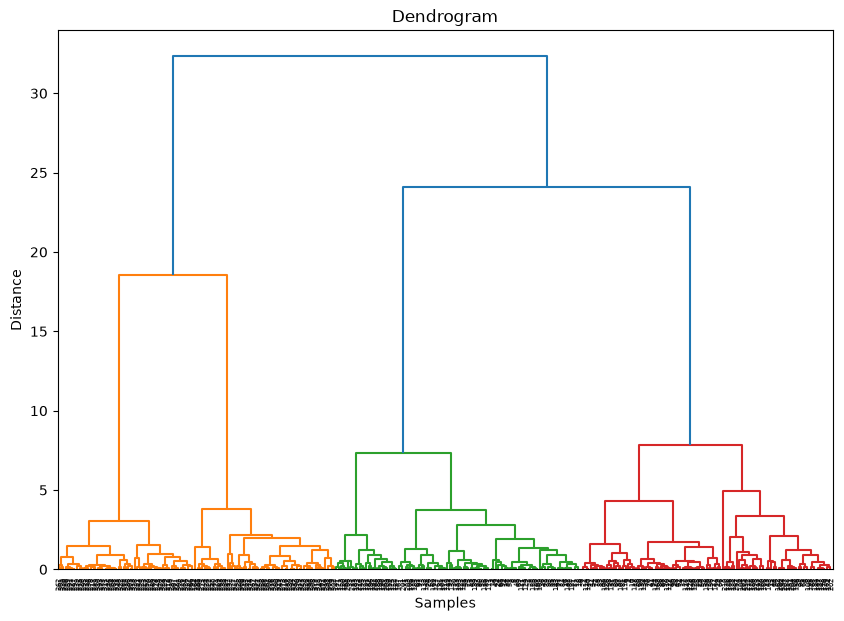

In [4]:
#Dendogram
plt.figure(figsize=(10, 7))
Z = linkage(df_pca, method='ward')
dendrogram(Z)
plt.title('Dendrogram')
plt.xlabel('Samples')
plt.ylabel('Distance')
plt.show()

Cluster= 2, silhoutte score 0.4706643066784682
Cluster= 3, silhoutte score 0.5464787009124682
Cluster= 4, silhoutte score 0.6435137463906256
Cluster= 5, silhoutte score 0.5801059310197499
Cluster= 6, silhoutte score 0.5507399020789187
Cluster= 7, silhoutte score 0.5520760038461715
Cluster= 8, silhoutte score 0.5405464643708063
Cluster= 9, silhoutte score 0.4835987811061473
Cluster= 10, silhoutte score 0.4443674702613168
Optimal: 4


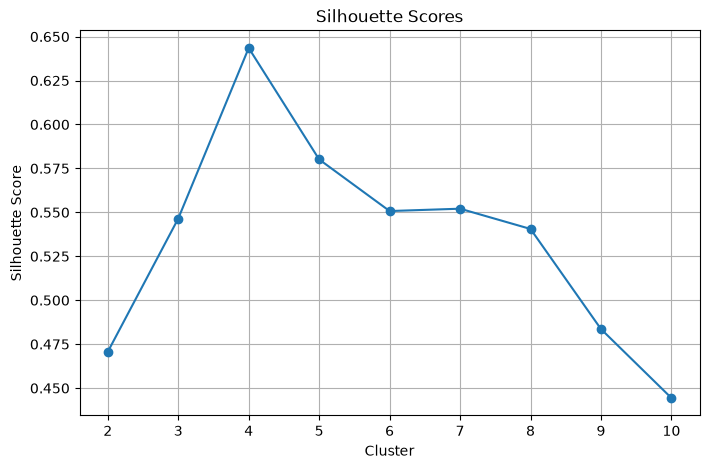

In [5]:
#Silhoutte score
silhouette_scores_hc = []
cluster_range = range(2, 11)
for n_clusters in cluster_range:
    hc = AgglomerativeClustering(n_clusters=n_clusters, metric='euclidean', linkage='ward')
    cluster_labels = hc.fit_predict(df_pca)
    silhouette_avg = silhouette_score(df_pca, cluster_labels)
    silhouette_scores_hc.append(silhouette_avg)
    print(f'Cluster= {n_clusters}, silhoutte score {silhouette_avg}')
optimal_clusters_hc = cluster_range[np.argmax(silhouette_scores_hc)]
print(f'Optimal: {optimal_clusters_hc}')
plt.figure(figsize=(8, 5))
plt.plot(cluster_range, silhouette_scores_hc, marker='o')
plt.title('Silhouette Scores')
plt.xlabel('Cluster')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

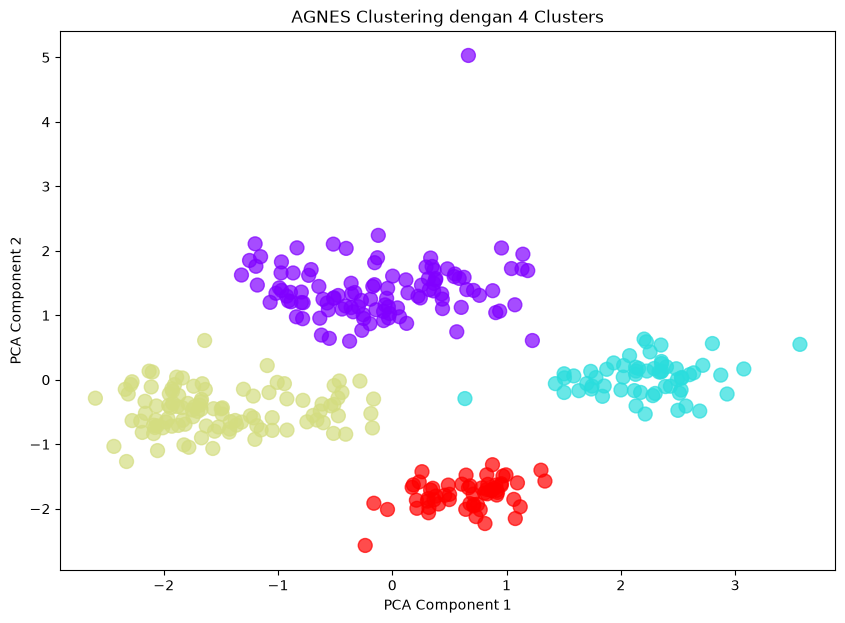

In [6]:
#Agnes
agnes = AgglomerativeClustering(n_clusters=optimal_clusters_hc, linkage='ward')
cluster_labels = agnes.fit_predict(df_pca)
#Visualisasi
plt.figure(figsize=(10, 7))
plt.scatter(df_pca[:, 0], df_pca[:, 1], c=cluster_labels, cmap='rainbow', s=100, alpha=0.7)
plt.title(f'AGNES Clustering dengan {optimal_clusters_hc} Clusters')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()